=== LOGISTIC REGRESSION RESULTS ===
Accuracy : 0.9906
Precision: 0.9781
Recall   : 0.9853
F1-Score : 0.9817

Classification Report:
               precision    recall  f1-score   support

   White (0)       0.99      0.99      0.99       792
     Red (1)       0.98      0.99      0.98       272

    accuracy                           0.99      1064
   macro avg       0.99      0.99      0.99      1064
weighted avg       0.99      0.99      0.99      1064



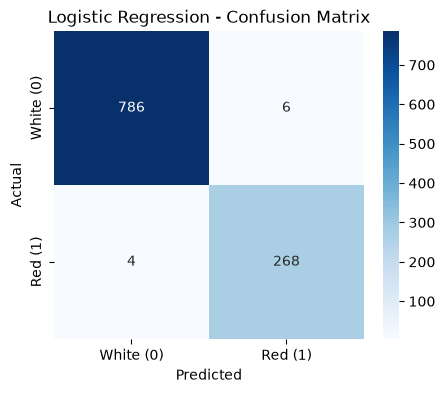

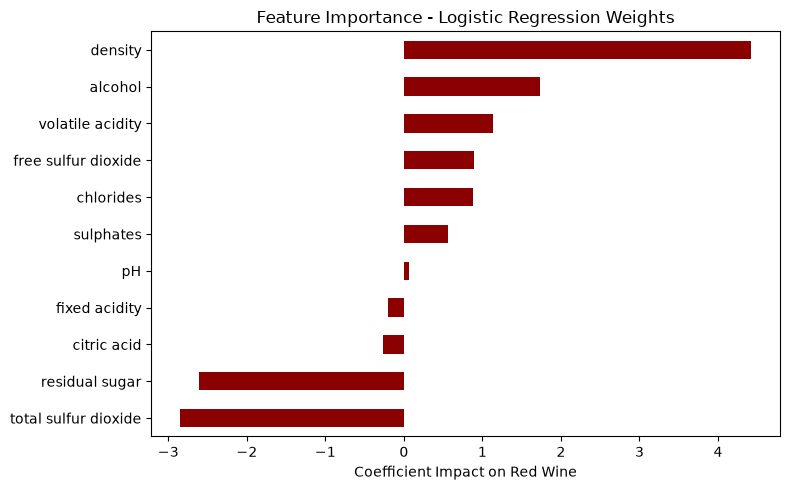

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# 1. Load Preprocessed Datasets
X_train = pd.read_csv("X_train_processed.csv")
X_test = pd.read_csv("X_test_processed.csv")
y_train = pd.read_csv("y_train.csv").values.ravel()
y_test = pd.read_csv("y_test.csv").values.ravel()

# 2. Train Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

# 3. Predict & Evaluate
y_pred_lr = lr_model.predict(X_test)

print("=== LOGISTIC REGRESSION RESULTS ===")
print(f"Accuracy : {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred_lr):.4f}")
print(f"F1-Score : {f1_score(y_test, y_pred_lr):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr, target_names=['White (0)', 'Red (1)']))

# 4. Confusion Matrix Heatmap
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Blues', 
            xticklabels=['White (0)', 'Red (1)'], yticklabels=['White (0)', 'Red (1)'])
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# 5. Feature Importance (Coefficients)
coef_series = pd.Series(lr_model.coef_[0], index=X_train.columns).sort_values()
plt.figure(figsize=(8, 5))
coef_series.plot(kind='barh', color='#8B0000')
plt.title("Feature Importance - Logistic Regression Weights")
plt.xlabel("Coefficient Impact on Red Wine")
plt.tight_layout()
plt.show()